# Magnetotelluric response: units, orientation and period

**Question:** How do the measured cl061 impedance components become apparent-resistivity and phase curves, and what can those curves not tell us?

**Level 1 — Foundations**  
**Prerequisites:** basic arrays and complex numbers; 25 min.


## Objectives

Which measured quantities are in the transfer function, how do XY and YX compare, and why is apparent resistivity not a depth sample?

## Setup

This lesson reads the attributed, committed cl061 derivative and uses NumPy and Matplotlib. It downloads nothing and fits no earth model. The final setup cell reports the exact imported package versions.

```bash
pip install numpy==2.2.6 matplotlib==3.10.8 scipy==1.15.2
```


In [1]:
# Record exact numerical-library versions used by this lesson.\nfrom importlib.metadata import version\nprint({name: version(name) for name in (\"numpy\", \"matplotlib\", \"scipy\")})\n

## Data

The exercise uses the 42-period measured Clear Lake cl061 EDI derivative with unknown subsurface truth. The USGS product and station record are cited below. The derivative is preserved separately from the seeded synthetic two-layer calibration; no synthetic truth is assigned to this measured station.

**Source and rights:** The USGS release is marked CC0; the station EDI requests citation. This repository uses the attributed derived QC record and does not mirror a raw EDI copy.


## Method

Magnetotellurics uses naturally varying electromagnetic fields. At a station, horizontal electric field is related to horizontal magnetic field by a frequency-dependent complex tensor. It is useful to begin with the measured response rather than immediately drawing a subsurface section: the complex values, units, orientation and frequency axis determine what any later transform can mean.

The product stores the impedance tensor as a 2 by 2 complex matrix at each frequency. In this case the two off-diagonal components are the primary response curves; the diagonal terms and their departures are retained for a separate dimensionality screen. The XY and YX labels refer to the declared component axes in the source frame. They must not be silently swapped, averaged, or rotated when the necessary geometry and covariance are unavailable.

With the harmonic convention recorded in the source processing chain, the relation is
$$\\mathbf{E}(f)=\\mathbf{Z}(f)\\mathbf{H}(f), \\qquad \\mathbf{Z}(f)=\\mathbf{Z}_{re}(f)+i\\mathbf{Z}_{im}(f).$$
Here f is frequency in hertz, E is the horizontal electric-field vector in volts per metre, H is the horizontal magnetic-field vector in tesla, and Z is impedance in ohms. The imaginary unit is i. A complex transfer function carries both amplitude and phase; discarding either part loses a distinct part of the observation.

For an off-diagonal component Zij, period and conventional apparent resistivity are
$$T=1/f, \\qquad \\rho_a=|Z_{ij}|^2/(\\mu_0 2\\pi f), \\qquad \\phi_{ij}=\\arg(Z_{ij}).$$
T is measured in seconds, mu0 is free-space permeability, rho_a is in ohm-metres, and phase phi is displayed in degrees. The code computes apparent resistivity independently from the stored complex tensor and compares it with the committed response values. Agreement is a reproducibility check of units and component mapping, not a validation of the source's geophysical interpretation.

The plotted phase convention is explicit: XY uses arg(Zxy), while the reciprocal YX curve uses arg(−Zyx), reported modulo 360 degrees. Apparent resistivity uses the magnitude and is unchanged by this sign. Retaining the sign convention is necessary when comparing oriented curves.\n\nThe word apparent matters. The formula transforms a surface transfer function into a scalar response using the uniform half-space reference relation. In a layered or multidimensional earth, the resulting curve depends on the integrated electromagnetic response and is not the true resistivity at one depth. A period is often associated with a characteristic diffusion scale. Under a uniform half-space approximation, delta is approximately sqrt(2 rho/(mu0 omega)); using omega=2 pi f and the conventional units gives roughly 503 sqrt(rho_a T) metres. That estimate is a scale guide only. Here the necessary 1D tensor screen fails, so the half-space depth estimate is not used to claim a cl061 investigation depth or layer boundary.

Inspect XY and YX separately. If they diverge, possible explanations include dimensionality, galvanic distortion, orientation errors, processing differences or uncertainty; a plot alone cannot choose among them. Frequency samples are not equally spaced in ordinary arithmetic, so the log-period axis displays the broad response range without pretending the sampling is uniform in linear period. The complex-plane plot traces real against imaginary impedance, with color showing period; it makes phase rotation and amplitude change visible without replacing the frequency-indexed curves.

For this measured station, response plots are a descriptive entry point. Its diagonal/antisymmetric departures fail the product's necessary 1D QC gate, its tipper has two missing periods, and the subsurface truth is unknown. Do not infer a 1D model from these curves. The next lesson applies the actual gate and shows its sensitivity. A separate synthetic calibration can teach forward/inverse behavior, but it remains a different data class and never supplies hidden truth for cl061.

A transfer-function record is downstream of time-series acquisition and processing, and it is not equivalent to the raw electric and magnetic traces. Instrument response, sensor orientation, site contact, remote-reference choices and estimator uncertainty can affect the estimated tensor. This repository exercise starts from an attributed EDI-derived response; it cannot audit every field acquisition choice from a response curve alone. For new data, carry the raw-file hash, station metadata, coordinate convention, rotation declaration, processing software/version and error representation alongside the numerical arrays.

The complex-plane view is especially useful for catching convention mistakes. A sign reversal moves a component by half a turn without changing its magnitude, so apparent resistivity alone cannot reveal a polarity problem. The plotted YX phase follows the product convention arg(−Zyx), while XY follows arg(Zxy); both are wrapped to positive degrees. This is why phase is compared against the stored orientation-specific response instead of recomputed with one unqualified angle formula. A robust data adapter must make those choices explicit and test them against an independent known response.

The colour in the complex-plane plot represents period, not depth. The plot traces each component through frequency space; it does not place a point at a location underground. Likewise, the 503 sqrt(rho_a T) scale is only a homogeneous-half-space guide. Conductivity contrasts, dimensionality, anisotropy and near-surface galvanic distortion alter the response. The necessary tensor screen in the next lesson is therefore a gate for a declared model family, not a proof of geological dimensionality.


The row ordering is part of the data contract: row k in the complex tensor, marginal-error array and period vector refers to the same frequency. Sorting only one array would create a plausible but false response curve. The example checks the recomputed curves against committed arrays before plotting, and the measured source identity is printed next to the result. In a field workflow, reject nonpositive or repeated frequencies and missing component values rather than filling gaps by interpolation. Keep both the original EDI and a derived receipt so a later rotation, phase wrap, or unit conversion can be traced to its input.


record: cl061 measured EDI transfer functions periods: 42 truth: None
computed response matches committed XY/YX curves within declared floating-point tolerance
QC eligibility recorded in source: False (response lesson does not invert)


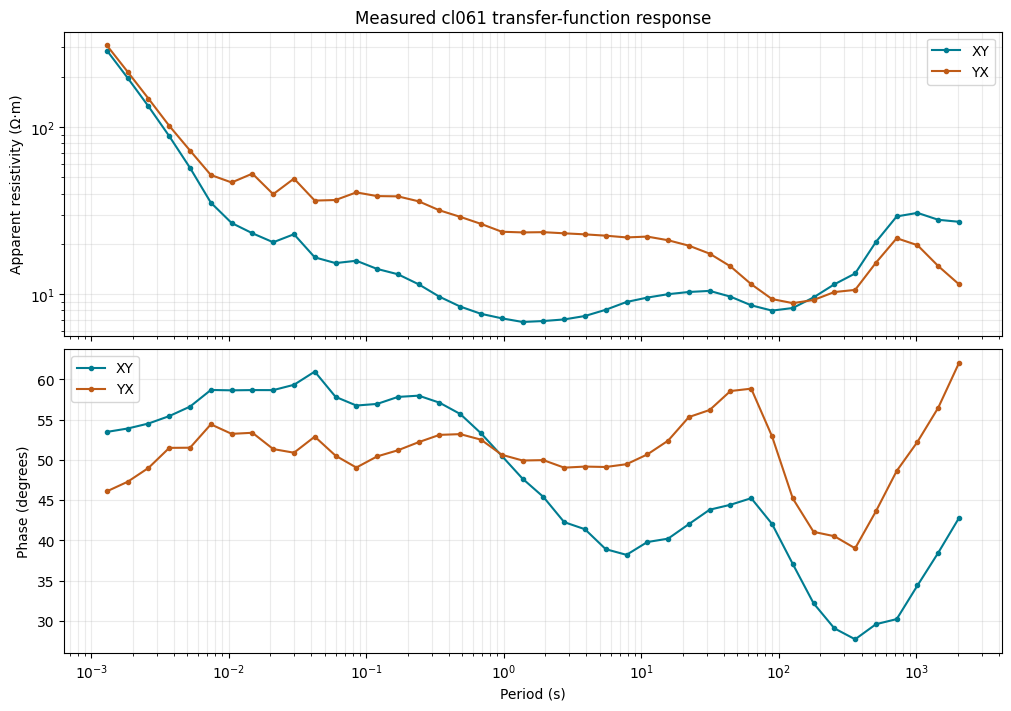

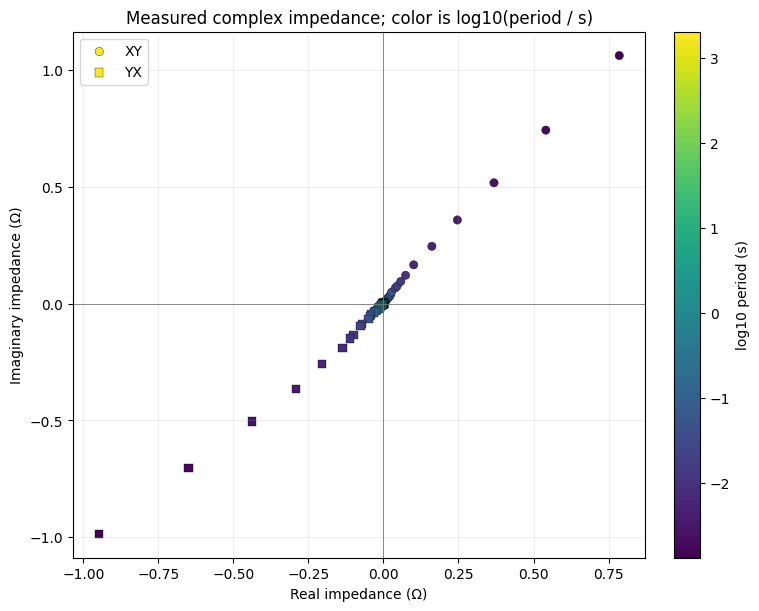

In [2]:
# Recompute the conventional response from the measured complex tensor and plot both orientations.
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
case = json.loads((root / "data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
frequency = np.asarray(case["frequencies_hz"], dtype=float)
period = 1.0 / frequency
z = np.asarray(case["tensor"]["real"], dtype=float) + 1j * np.asarray(case["tensor"]["imag"], dtype=float)
mu0 = 4e-7 * np.pi
computed = {}
for component in ("xy", "yx"):
    i, j = (0, 1) if component == "xy" else (1, 0)
    rho = np.abs(z[:, i, j])**2 / (mu0 * 2 * np.pi * frequency)
    phase_impedance = z[:, i, j] if component == "xy" else -z[:, i, j]
    phase = np.mod(np.rad2deg(np.angle(phase_impedance)), 360.0)
    stored = case["observed"][component]
    computed[component] = (rho, phase)
    assert np.allclose(rho, stored["apparent"], rtol=2e-10, atol=1e-10)
    assert np.allclose(phase, stored["phase"], rtol=0, atol=1e-10)
print("record:", case["id"], case["source_kind"], "periods:", len(period), "truth:", case["truth"])
print("computed response matches committed XY/YX curves within declared floating-point tolerance")
print("QC eligibility recorded in source:", case["one_d_inversion_eligible"], "(response lesson does not invert)")

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True, sharex=True)
for component, color in (("xy", "#007c91"), ("yx", "#bf5b17")):
    rho, phase = computed[component]
    axes[0].loglog(period, rho, ".-", color=color, label=component.upper())
    axes[1].semilogx(period, phase, ".-", color=color, label=component.upper())
axes[0].set_ylabel("Apparent resistivity (Ω·m)")
axes[0].set_title("Measured cl061 transfer-function response")
axes[1].set_ylabel("Phase (degrees)")
axes[1].set_xlabel("Period (s)")
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
    axis.legend()
plt.show()

fig_complex, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
for component, marker in (("xy", "o"), ("yx", "s")):
    i, j = (0, 1) if component == "xy" else (1, 0)
    points = ax.scatter(z[:, i, j].real, z[:, i, j].imag, c=np.log10(period),
                        cmap="viridis", marker=marker, label=component.upper(),
                        edgecolors="black", linewidths=0.25)
ax.set_xlabel("Real impedance (Ω)")
ax.set_ylabel("Imaginary impedance (Ω)")
ax.set_title("Measured complex impedance; color is log10(period / s)")
ax.axhline(0, color="#777777", lw=0.6)
ax.axvline(0, color="#777777", lw=0.6)
ax.grid(True, alpha=0.2)
ax.legend()
fig_complex.colorbar(points, ax=ax, label="log10 period (s)")
plt.show()


The response curves show the measured orientations and preserve phase; the complex-plane view shows how each transfer function changes with period. Both are observations at the station. The equality check above confirms the implemented units and mapping reproduce the committed display arrays. Neither plot supplies a layered model or changes the QC-only decision.

## Results

The impedance-to-response calculation reproduces both committed orientations within floating-point tolerance. For phase, the product uses arg(Zxy) and arg(−Zyx), wrapped to 0–360 degrees; apparent resistivity depends on magnitude and is unchanged by that sign. The plots describe surface observations only. They do not estimate layer resistivity or investigation depth. cl061 remains measured QC data with unknown subsurface truth in this exercise.

## Summary

Apparent resistivity and phase are derived views of the complex surface impedance. Their physical meaning depends on units, frame, frequency and dimensionality. The measured cl061 record fails the declared 1D screen and has no known subsurface truth here; use the plots for response QC, not depth-labelled geology.

## References

- [Caldwell, Bibby & Brown (2004), The magnetotelluric phase tensor](https://doi.org/10.1111/j.1365-246X.2004.02281.x)
- [USGS Clear Lake magnetotelluric data release](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)
- [EarthScope/USGS cl061 station product](https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061)
- [Kirkby et al. (2019), MTPy software, JOSS DOI 10.21105/joss.01358](https://doi.org/10.21105/joss.01358)
- [Krieger & Peacock (2014), MTpy toolbox, DOI 10.1016/j.cageo.2014.07.013](https://doi.org/10.1016/j.cageo.2014.07.013)